# Feature Engineering - определение факта сделки на Авито
**Задача:** бинарная классификация `is_deal`.

Цель - подготовить признаки на уровне объявления и сравнить их вклад в качество логистической регрессии.

## 1. Загрузка данных и базовые проверки
### 1.1. Библиотеки и вспомогательные функции

In [1]:
import os
from pathlib import Path

repo_root = Path.cwd()
if repo_root.name in {"analysis", "feature", "models"}:
    repo_root = repo_root.parent

assert (repo_root / "requirements.txt").is_file() and (repo_root / "data/listings.csv").is_file(), (
    "Запустите ноутбук из корня репозитория или из папки, в которой он лежит"
)
os.chdir(repo_root)

In [2]:
from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display

In [3]:
for path in sorted(Path("data").rglob("*.csv")):
    print(path)


def safe_divide(numerator, denominator):
    return numerator / denominator.replace(0, np.nan)

data\data_ONLY_anomailes\anomalies_bad_time\events_anomalies_bad_time.csv
data\data_ONLY_anomailes\anomalies_bad_time\listings_anomalies_bad_time.csv
data\data_ONLY_anomailes\anomalies_bad_time\messages_anomalies_bad_time.csv
data\data_ONLY_anomailes\anomalies_bad_time\surveys_anomalies_bad_time.csv
data\data_ONLY_anomailes\anomalies_high_listing_ids\events_anomalies_high_listing_ids.csv
data\data_ONLY_anomailes\anomalies_high_listing_ids\listings_anomalies_high_listing_ids.csv
data\data_ONLY_anomailes\anomalies_high_listing_ids\messages_anomalies_high_listing_ids.csv
data\data_ONLY_anomailes\anomalies_high_listing_ids\surveys_anomalies_high_listing_ids.csv
data\data_ONLY_anomailes\anomalies_low_listing_ids\events_anomalies_low_listing_ids.csv
data\data_ONLY_anomailes\anomalies_low_listing_ids\listings_anomalies_low_listing_ids.csv
data\data_ONLY_anomailes\anomalies_low_listing_ids\messages_anomalies_low_listing_ids.csv
data\data_ONLY_anomailes\anomalies_low_listing_ids\surveys_anomali

### 1.2. Чтение исходных таблиц
Пути соответствуют структуре репозитория команды. Проверяем размеры, типы, пропуски и дубликаты.

In [4]:
DATA = Path("data/data_wthout_anomailes")

listings = pd.read_csv(DATA / "listings_wthout_anomailes.csv")
events = pd.read_csv(DATA / "events_wthout_anomailes.csv")
messages = pd.read_csv(DATA / "messages_wthout_anomailes.csv")
surveys = pd.read_csv(DATA / "surveys_wthout_anomailes.csv")

verified = pd.read_csv("data/verified.csv")

tables = {
    "listings": listings,
    "events": events,
    "messages": messages,
    "surveys": surveys,
    "verified": verified
}

for name, df in tables.items():
    print(f"\n{name}: {df.shape}")
    print(df.dtypes)
    print("Дубликатов:", df.duplicated().sum())
    print("Пропуски:")
    print(df.isna().sum())


listings: (15274, 18)
listing_id              int64
seller_id               int64
seller_type               str
category                  str
title                     str
price                 float64
current_price         float64
photos_count            int64
description_length    float64
region                    str
published_at              str
closed_at                 str
close_type                str
views_total             int64
favorites_total         int64
phone_views_total       int64
chats_total             int64
messages_total          int64
dtype: object
Дубликатов: 0
Пропуски:
listing_id              0
seller_id               0
seller_type             0
category              381
title                   0
price                 183
current_price         183
photos_count            0
description_length    458
region                  0
published_at           40
closed_at              40
close_type              0
views_total             0
favorites_total         0
phone_vie

In [5]:
# Проверка ключей перед построением признаков.
assert listings["listing_id"].is_unique, "В listings есть повторяющиеся ID"
assert verified["listing_id"].is_unique, "В verified есть повторяющиеся ID"
assert verified["is_deal"].isin([0, 1]).all(), "Некорректная разметка"

## 2. Listings - признаки объявления
### 2.1. Исследование данных
Отбираем размеченные объявления, присутствующие в очищенной таблице. Идентификаторы не используются как признаки модели.

In [6]:
display(listings.head())
display(listings.describe().T)

for col in ["seller_type", "category", "region", "close_type"]:
    print(f"\n{col}:")
    print(listings[col].value_counts(dropna=False))

verified_clean = verified[
    verified["listing_id"].isin(listings["listing_id"])
]

print("Всего verified:", len(verified))
print("После очистки:", len(verified_clean))
print(verified_clean["is_deal"].value_counts())

,listing_id,seller_id,seller_type,category,title,price,current_price,photos_count,description_length,region,published_at,closed_at,close_type,views_total,favorites_total,phone_views_total,chats_total,messages_total
0,132065,31904,private,Одежда и обувь,Пуховик женский б/у,570.0,470.0,3,130.0,Москва,2026-09-07 19:40:26,2026-09-22 11:05:13,снято продавцом,193,10,0,4,21
1,131440,31664,private,Одежда и обувь,Рюкзак городской с документами,NaN,NaN,3,39.0,Санкт-Петербург,2026-09-07 09:55:11,2026-09-11 20:55:35,снято продавцом,21,2,0,0,0
2,117997,24387,private,Мебель и интерьер,Комод,2080.0,2080.0,6,128.0,СПб,2026-08-22 18:11:20,2026-09-06 17:09:12,снято продавцом,140,6,1,4,25
3,129810,20372,private,Одежда и обувь,Пуховик женский б/у,1320.0,1320.0,8,202.0,Москва,2026-09-05 16:07:34,2026-09-08 15:10:57,снято продавцом,50,1,0,4,23
4,111780,13149,private,Спорт и отдых,Спальный мешок,5030.0,5030.0,3,82.0,Санкт-Петербург,2026-08-15 14:31:56,2026-09-14 14:31:56,истёк срок,245,9,2,10,44


,count,mean,std,min,25%,50%,75%,max
listing_id,15274.0,130639.293178,17664.059807,100004.0,115439.25,130524.5,145951.25,161269.0
seller_id,15274.0,23047.930405,8706.428836,10001.0,15313.25,21985.0,30008.75,41169.0
price,15091.0,7703.314558,8379.213690,120.0,2290.00,4900.0,9960.00,105640.0
current_price,15091.0,7479.169041,8149.489526,120.0,2220.00,4760.0,9640.00,105640.0
photos_count,15274.0,4.239034,2.178421,0.0,3.00,4.0,6.00,10.0
description_length,14816.0,141.522881,126.762915,9.0,65.00,105.0,174.00,1997.0
views_total,15274.0,137.177622,148.304019,0.0,37.00,83.0,189.75,1624.0
favorites_total,15274.0,4.488870,5.059177,0.0,1.00,3.0,6.00,49.0
phone_views_total,15274.0,1.388307,1.918389,0.0,0.00,1.0,2.00,20.0
chats_total,15274.0,5.805421,6.625386,0.0,2.00,3.0,8.00,70.0



seller_type:
seller_type
private     13848
business     1426
Name: count, dtype: int64

category:
category
Электроника              3300
Одежда и обувь           3209
Детские товары           2062
Мебель и интерьер        1894
Запчасти и аксессуары    1567
Бытовая техника          1535
Спорт и отдых            1326
NaN                       381
Name: count, dtype: int64

region:
region
Москва             4175
Санкт-Петербург    2818
Краснодар          1301
Новосибирск        1245
Екатеринбург       1245
Казань             1208
Нижний Новгород    1076
Самара              985
Москва              104
Moscow               93
г. Москва            88
москва               81
краснодар            71
СПб                  69
Питер                64
санкт-петербург      59
г. Краснодар         59
самара               57
г. Казань            56
казань               56
екатеринбург         55
Санкт Петербург      51
Екб                  48
г. Новосибирск       46
нижний новгород      43
новосибирс

### 2.2. Нормализация региона
Приводим разные написания одного города к единому значению. Рабочая таблица `features` начинается с копии listings.

In [7]:
features = listings.copy()

features["region"] = (
    features["region"]
    .str.strip()
    .str.lower()
    .str.replace(r"^г\.\s*", "", regex=True)
)

region_map = {
    "moscow": "москва",
    "масква" : "москва",
    "мск" : "москва",
    "спб": "санкт-петербург",
    "санкт-питербург" : "санкт-петербург",
    "msk" : "москва",
    "питер": "санкт-петербург",
    "санкт петербург": "санкт-петербург",
    "екб": "екатеринбург",
    "новосиб" : "новосибирск",
    "н. новгород": "нижний новгород"
}

features["region"] = features["region"].replace(region_map)

print(features["region"].value_counts())

region
москва             4541
санкт-петербург    3061
краснодар          1431
екатеринбург       1348
новосибирск        1332
казань             1320
нижний новгород    1158
самара             1083
Name: count, dtype: int64


### 2.3. Восстановление категорий и индикатор пропусков
Проверяем однозначность соответствия заголовка категории. Пропуски длины описания оставляем для импутации в модели и отмечаем бинарным флагом.

In [8]:
print("Всего объявлений:", len(features))
print("Уникальных заголовков:", features["title"].nunique())

display(features["title"].value_counts().head(20))

display(
    features.loc[
        features["category"].isna(),
        ["title", "price", "category"]
    ].head(30)
)

title_categories = (
    features.dropna(subset=["category"])
    .groupby("title")["category"]
    .nunique()
)

print(title_categories.value_counts())

features["description_missing"] = (
    features["description_length"].isna().astype(int)
)

Всего объявлений: 15274
Уникальных заголовков: 720


title
Рюкзак городской               95
Кроссовки Nike                 89
Худи оверсайз                  81
Джинсы Levi's                  80
Колонка JBL                    76
Видеокарта GTX 1660            75
Смартфон Samsung Galaxy A52    73
Свитер вязаный                 73
Платье вечернее                72
Сапоги зимние                  70
Наушники беспроводные          69
Фотоаппарат Canon              69
Костюм мужской                 69
Электронная книга              66
Монитор 24 дюйма               65
Пальто шерстяное               63
Ботинки кожаные                63
Игровая приставка              62
Планшет Huawei MatePad         61
Пуховик женский                60
Name: count, dtype: int64

,title,price,category
6,Кроссовки Nike,NaN,NaN
8,Наушники беспроводные с документами,7510.0,NaN
110,Электроплита,11130.0,NaN
156,Стеллаж,2890.0,NaN
215,Роутер Wi-Fi новый,12830.0,NaN
216,iPhone 12 128 ГБ с документами,4680.0,NaN
286,Кофемашина DeLonghi отличное состояние,10570.0,NaN
347,Умные часы б/у,15610.0,NaN
358,Автокресло новый,11960.0,NaN
407,Смартфон Samsung Galaxy A52 как новый,33270.0,NaN


category
1    720
Name: count, dtype: int64


In [9]:
# Восстановление категории по известным заголовкам.

title_to_category = (
    features.dropna(subset=["category"])
    .groupby("title")["category"]
    .first()
    .to_dict()
)

features["category"] = features["category"].fillna(
    features["title"].map(title_to_category)
)

print("Осталось пропусков:", features["category"].isna().sum())

Осталось пропусков: 0


### 2.4. Заголовки и относительная цена
Выделяем состояние товара и другие суффиксы, затем убираем их для получения базового названия товара. Медианная цена группы позволяет сравнивать разные товары на общей шкале.

In [10]:
title = features["title"].str.lower().str.strip()

features["is_used"] = title.str.endswith(" б/у").astype(int)
features["is_new"] = (
    title.str.endswith(" новый")
    & ~title.str.endswith(" как новый")
).astype(int)

features["is_like_new"] = title.str.endswith(" как новый").astype(int)
features["has_documents"] = title.str.endswith(" с документами").astype(int)
features["is_negotiable"] = title.str.endswith(" торг").astype(int)
features["is_urgent"] = title.str.endswith(" срочно").astype(int)
features["is_excellent"] = title.str.endswith(" отличное состояние").astype(int)
features["has_package"] = title.str.contains(
    r"\b(?:коробка|коробкой|упаковка|упаковкой)\b",
    case=False,
    na=False
).astype(int)

suffix_pattern = (
    r"\s+(?:в хорошем состоянии|отличное состояние|"
    r"с документами|как новый|б/у|новый|торг|срочно)$"
)

features["base_title"] = title.str.replace(
    suffix_pattern, "", regex=True
)

features["is_good_condition"] = (
    title.str.endswith(" в хорошем состоянии").astype(int)
)

print("Товарных групп:", features["base_title"].nunique())
print(features["base_title"].value_counts().describe())

print("До:", features["title"].nunique())
print("После:", features["base_title"].nunique())

display(features["base_title"].value_counts().head(20))

# относительная цена

features["product_median_price"] = (
    features.groupby("base_title")["price"].transform("median")
)

features["relative_price"] = (
    features["price"] / features["product_median_price"]
)

features["relative_current_price"] = (
    features["current_price"] / features["product_median_price"]
)

features["log_relative_price"] = np.log(
    features["relative_price"]
)

display(
    features[
        [
            "title",
            "base_title",
            "category",
            "price",
            "product_median_price",
            "relative_price"
        ]
    ].head(15)
)

print(features["relative_price"].describe())

print(
    features["base_title"].value_counts().describe()
)

Товарных групп: 80
count     80.000000
mean     190.925000
std       52.265092
min      111.000000
25%      147.750000
50%      176.000000
75%      235.250000
max      309.000000
Name: count, dtype: float64
До: 720
После: 80


base_title
худи оверсайз             309
рюкзак городской          300
кроссовки nike            300
платье вечернее           291
костюм мужской            279
сапоги зимние             275
джинсы levi's             274
видеокарта gtx 1660       267
пальто шерстяное          266
пуховик женский           261
iphone 12 128 гб          258
наушники беспроводные     257
свитер вязаный            256
колонка jbl               256
ботинки кожаные           252
планшет huawei matepad    252
электронная книга         248
фотоаппарат canon         247
игровая приставка         245
ноутбук lenovo ideapad    239
Name: count, dtype: int64

,title,base_title,category,price,product_median_price,relative_price
0,Пуховик женский б/у,пуховик женский,Одежда и обувь,570.0,1530.0,0.372549
1,Рюкзак городской с документами,рюкзак городской,Одежда и обувь,NaN,1615.0,NaN
2,Комод,комод,Мебель и интерьер,2080.0,6510.0,0.319508
3,Пуховик женский б/у,пуховик женский,Одежда и обувь,1320.0,1530.0,0.862745
4,Спальный мешок,спальный мешок,Спорт и отдых,5030.0,5690.0,0.884007
5,Смартфон Samsung Galaxy A52 как новый,смартфон samsung galaxy a52,Электроника,15880.0,14665.0,1.082850
6,Кроссовки Nike,кроссовки nike,Одежда и обувь,NaN,1510.0,NaN
7,Самокат взрослый как новый,самокат взрослый,Спорт и отдых,5700.0,4885.0,1.166837
8,Наушники беспроводные с документами,наушники беспроводные,Электроника,7510.0,14680.0,0.511580
9,Тормозные колодки б/у,тормозные колодки,Запчасти и аксессуары,3500.0,4015.0,0.871731


count    15091.000000
mean         1.199346
std          0.793227
min          0.068966
25%          0.666667
50%          1.000000
75%          1.495726
max         10.065359
Name: relative_price, dtype: float64
count     80.000000
mean     190.925000
std       52.265092
min      111.000000
25%      147.750000
50%      176.000000
75%      235.250000
max      309.000000
Name: count, dtype: float64


### 2.5. Исследование ценовых признаков
Сопоставляем относительную цену с проверенной разметкой; группы цен используются только для анализа, не как признаки модели.

в хорошем состоянии    80
отличное состояние     80
с документами          80
как новый              80
срочно                 80
новый                  80
торг                   80
б/у                    80
Name: count, dtype: int64

(300, 34)


is_deal                                  0            1
price                  mean    8126.277778  8133.652174
                       median  4910.000000  5690.000000
                       std     9368.096581  8700.491046
relative_price         mean       1.390165     1.133492
                       median     1.154834     0.948571
                       std        1.030458     0.737397
relative_current_price mean       1.358441     1.098813
                       median     1.111190     0.921141
                       std        1.024936     0.740504
log_relative_price     mean       0.121607    -0.059337
                       median     0.143841    -0.052798
                       std        0.638345     0.614893

,total,deals,deal_rate
price_group,,,
Очень дешёвый,34,16,0.470588
Дешёвый,65,31,0.476923
Рыночная цена,68,26,0.382353
Дорогой,39,17,0.435897
Очень дорогой,89,25,0.280899


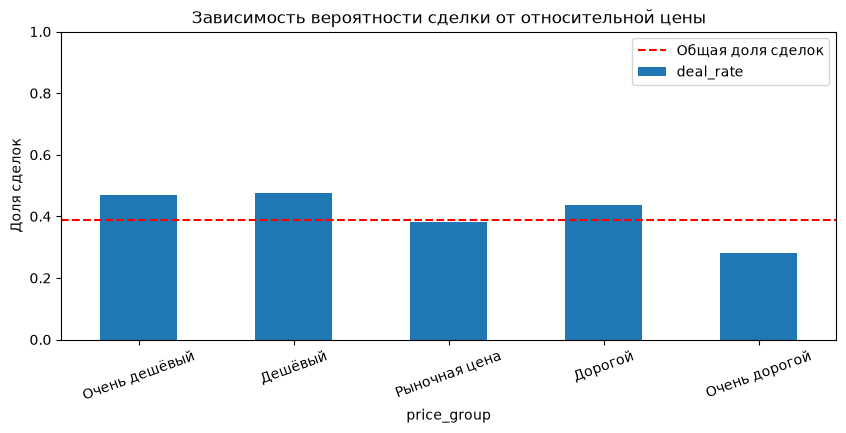

In [11]:
unique_titles = sorted(
    title.dropna().unique(),
    key=len,
    reverse=True
)

suffixes = []

for full_title in unique_titles:
    for short_title in unique_titles:
        if full_title.startswith(short_title + " "):
            suffix = full_title[len(short_title):].strip()
            suffixes.append(suffix)
            break

display(pd.Series(suffixes).value_counts())

research = features.merge(
    verified,
    on="listing_id",
    how="inner",
    validate="one_to_one"
)

print(research.shape)

display(
    research.groupby("is_deal")[
        [
            "price",
            "relative_price",
            "relative_current_price",
            "log_relative_price"
        ]
    ].agg(["mean", "median", "std"]).T
)

research["price_group"] = pd.cut(
    research["relative_price"],
    bins=[0, 0.5, 0.8, 1.2, 1.5, np.inf],
    labels=[
        "Очень дешёвый",
        "Дешёвый",
        "Рыночная цена",
        "Дорогой",
        "Очень дорогой"
    ]
)

price_stats = (
    research.groupby("price_group", observed=True)
    .agg(
        total=("is_deal", "count"),
        deals=("is_deal", "sum"),
        deal_rate=("is_deal", "mean")
    )
)

display(price_stats)

price_stats["deal_rate"].plot(
    kind="bar",
    figsize=(10, 4),
    rot=20,
    title="Зависимость вероятности сделки от относительной цены"
)

plt.axhline(
    research["is_deal"].mean(),
    color="red",
    linestyle="--",
    label="Общая доля сделок"
)

plt.ylabel("Доля сделок")
plt.ylim(0, 1)
plt.legend()
plt.show()

### 2.6. Скидка, время жизни и способ закрытия
Считаем изменение цены и длительность размещения. Проверяем, связаны ли срок жизни и способ закрытия с фактом сделки; закрытие само по себе не гарантирует продажу.

In [12]:
# Относительная величина снижения цены
features["discount_pct"] = (
    (features["price"] - features["current_price"])
    / features["price"]
)

# Снижалась ли цена к моменту закрытия
features["has_discount"] = (
    (features["current_price"] < features["price"])
    .astype(int)
    .where(features[["price", "current_price"]].notna().all(axis=1))
)

# Цена существенно выше медианы
features["is_overpriced"] = (
    (features["relative_price"] > 1.5)
    .astype(int)
    .where(features["relative_price"].notna())
)

# Логарифм абсолютной цены
features["log_price"] = np.log1p(features["price"])

features["published_at"] = pd.to_datetime(
    features["published_at"]
)

features["closed_at"] = pd.to_datetime(
    features["closed_at"]
)

features["lifetime_hours"] = (
    features["closed_at"] - features["published_at"]
).dt.total_seconds() / 3600

features["lifetime_days"] = features["lifetime_hours"] / 24

display(features["lifetime_days"].describe())

features["is_closed_first_day"] = (
    (features["lifetime_days"] <= 1)
    .astype(int)
    .where(features["lifetime_days"].notna())
)

features["is_closed_first_week"] = (
    (features["lifetime_days"] <= 7)
    .astype(int)
    .where(features["lifetime_days"].notna())
)

features["log_lifetime"] = np.log1p(
    features["lifetime_days"]
)

research = features.merge(
    verified, on="listing_id", how="inner"
)

display(
    research.groupby("is_deal")["lifetime_days"]
    .agg(["mean", "median", "std", "min", "max"])
)

research["lifetime_group"] = pd.cut(
    research["lifetime_days"],
    bins=[0, 1, 3, 7, 14, 29, np.inf],
    labels=[
        "До 1 дня",
        "1–3 дня",
        "3–7 дней",
        "7–14 дней",
        "14–29 дней",
        "Более 29 дней"
    ],
    include_lowest=True
)

lifetime_stats = (
    research.groupby("lifetime_group", observed=True)
    .agg(
        total=("is_deal", "count"),
        deals=("is_deal", "sum"),
        deal_rate=("is_deal", "mean")
    )
)

display(lifetime_stats)

display(
    research.groupby("close_type")
    .agg(
        total=("is_deal", "count"),
        deals=("is_deal", "sum"),
        deal_rate=("is_deal", "mean")
    )
)

count    15234.000000
mean        14.841261
std         11.831122
min          0.061238
25%          4.132977
50%          9.443021
75%         30.000000
max         30.000000
Name: lifetime_days, dtype: float64

,mean,median,std,min,max
is_deal,,,,,
0,16.515788,11.929664,12.210002,0.590313,30.0
1,12.478145,8.411007,10.542979,0.814468,30.0


,total,deals,deal_rate
lifetime_group,,,
До 1 дня,5,1,0.200000
1–3 дня,40,12,0.300000
3–7 дней,69,38,0.550725
7–14 дней,65,31,0.476923
14–29 дней,14,6,0.428571
Более 29 дней,106,27,0.254717


,total,deals,deal_rate
close_type,,,
заблокировано,2,0,0.000000
истёк срок,106,27,0.254717
снято продавцом,192,89,0.463542


In [13]:
# Проверка связи длительности объявления со способом его закрытия.

display(pd.crosstab(
    research["lifetime_group"],
    research["close_type"]
))

close_type,заблокировано,истёк срок,снято продавцом
lifetime_group,,,
До 1 дня,0,0,5
1–3 дня,2,0,38
3–7 дней,0,0,69
7–14 дней,0,0,65
14–29 дней,0,0,14
Более 29 дней,0,106,0


In [14]:
# Анализ только объявлений, снятых продавцом.

display(
    research[
        research["close_type"] == "снято продавцом"
    ]
    .groupby("lifetime_group", observed=True)["is_deal"]
    .agg(["count", "sum", "mean"])
)

,count,sum,mean
lifetime_group,,,
До 1 дня,5,1,0.200000
1–3 дня,38,12,0.315789
3–7 дней,69,38,0.550725
7–14 дней,65,31,0.476923
14–29 дней,14,6,0.428571


### 2.7. Поведенческие признаки
Нормируем количество действий по просмотрам, чатам и времени жизни. `safe_divide` оставляет NaN, если знаменатель равен нулю; при расчёте дневной активности минимальный срок - один день.

In [15]:
# Конверсии просмотров в контактные действия и глубина переписки.

features["messages_per_chat"] = safe_divide(
    features["messages_total"],
    features["chats_total"]
)

features["chats_per_view"] = safe_divide(
    features["chats_total"],
    features["views_total"]
)

features["phones_per_view"] = safe_divide(
    features["phone_views_total"],
    features["views_total"]
)

features["favorites_per_view"] = safe_divide(
    features["favorites_total"],
    features["views_total"]
)

features["contacts_total"] = (
    features["chats_total"]
    + features["phone_views_total"]
)

features["contacts_per_view"] = safe_divide(
    features["contacts_total"],
    features["views_total"]
)

In [16]:
# Интенсивность активности за день.

days = features["lifetime_days"].clip(lower=1)

features["views_per_day"] = (
    features["views_total"] / days
)

features["chats_per_day"] = (
    features["chats_total"] / days
)

features["messages_per_day"] = (
    features["messages_total"] / days
)

features["contacts_per_day"] = (
    features["contacts_total"] / days
)

### 2.8. Относительные характеристики внутри товарной группы
Сравниваем активность, длину описания и время жизни с медианами похожих товаров. Не все экспериментальные признаки попадут в итоговый набор.

In [17]:
# относительная популярность товара по просмотрам

features["views_per_day_median"] = (
    features.groupby("base_title")["views_per_day"]
    .transform("median")
)

features["relative_views_per_day"] = safe_divide(
    features["views_per_day"],
    features["views_per_day_median"]
)

# относительная популярность товара по сообщениям

features["median_messages_per_chat"] = (
    features.groupby("base_title")["messages_per_chat"]
    .transform("median")
)

features["relative_messages_per_chat"] = safe_divide(
    features["messages_per_chat"],
    features["median_messages_per_chat"]
)

# относительная популярность товара по длине описания

features["median_description_length"] = (
    features.groupby("base_title")["description_length"]
    .transform("median")
)

features["relative_description_length"] = safe_divide(
    features["description_length"],
    features["median_description_length"]
)

# относительная популярность товара lifetime товара

features["median_lifetime_days"] = (
    features.groupby("base_title")["lifetime_days"]
    .transform("median")
)

features["relative_lifetime_days"] = safe_divide(
    features["lifetime_days"],
    features["median_lifetime_days"]
)

### 2.9. Отсутствие просмотров и контактов
Отдельные бинарные признаки позволяют различать отсутствие событий и пропуски в относительных величинах.

In [18]:
features["no_contacts"] = (
    features["contacts_total"] == 0
).astype(int)

features["no_chats"] = (
    features["chats_total"] == 0
).astype(int)

features["no_phone_views"] = (
    features["phone_views_total"] == 0
).astype(int)

features["no_views"] = (
    features["views_total"] == 0
).astype(int)

## 3. Surveys - ответы продавцов
### 3.1. Проверка ответов и исследование достоверности
Опрос доступен частным продавцам, снявшим объявление. Ответ - сигнал, но не целевая переменная: по сохранённым результатам 41 из 51 ответа «Продал на Авито» подтверждён разметкой. Намеренный обман из этих данных установить нельзя.

In [19]:
display(surveys.head(10))

print("Размер:", surveys.shape)

print("\nПропуски:")
print(surveys.isna().sum())

print("\nВарианты ответов:")
print(surveys["answer"].value_counts(dropna=False))

print("\nДубликаты строк:")
print(surveys.duplicated().sum())

print("\nПовторяющиеся listing_id:")
print(surveys["listing_id"].duplicated().sum())

survey_conflicts = (
    surveys.groupby("listing_id")["answer"]
    .nunique()
)

display(survey_conflicts.value_counts())

# Разделение ответов по столбцам
answers_count = surveys["answer"].value_counts()

for answer_type in answers_count.index.tolist():
    surveys[f"answer_type_{answer_type}"] = (
        surveys["answer"] == answer_type
    ).astype(int)

# Мог ли продавец получить опрос
features["survey_eligible"] = (
    (features["seller_type"] == "private")
    & (features["close_type"] == "снято продавцом")
).astype(int)

# Есть ли непустой ответ на опрос
features["survey_answered"] = (
    features["listing_id"].isin(
        surveys.loc[surveys["answer"].notna(), "listing_id"]
    )
).astype(int)

# Сопоставление ответов с проверенной разметкой.
survey_research = (
    surveys[["listing_id", "answer"]]
    .drop_duplicates()
    .merge(verified_clean, on="listing_id", how="inner")
)

display(
    survey_research.groupby("answer")
    .agg(
        total=("is_deal", "count"),
        deals=("is_deal", "sum"),
        deal_rate=("is_deal", "mean")
    )
)

,listing_id,answered_at,platform,answer
0,100227,2026-08-02 10:38:45,ios,Передумал продавать
1,100431,2026-08-02 19:04:57,android,Продал в другом месте
2,100724,2026-08-02 19:49:59,web,Продал в другом месте
3,100551,2026-08-02 19:58:47,android,Передумал продавать
4,100476,2026-08-02 20:23:51,android,Продал в другом месте
5,100729,2026-08-03 08:20:57,android,Продал в другом месте
6,101270,2026-08-03 09:08:28,ios,Продал в другом месте
7,100402,2026-08-03 10:37:32,android,Продал в другом месте
8,100212,2026-08-03 11:56:04,ios,Продал на Авито
9,101248,2026-08-03 15:29:23,web,Продал на Авито


Размер: (5942, 4)

Пропуски:
listing_id     0
answered_at    0
platform       0
answer         0
dtype: int64

Варианты ответов:
answer
Продал на Авито          2480
Продал в другом месте    1667
Передумал продавать      1125
Другая причина            670
Name: count, dtype: int64

Дубликаты строк:
0

Повторяющиеся listing_id:
0


answer
1    5942
Name: count, dtype: int64

,total,deals,deal_rate
answer,,,
Другая причина,16,6,0.375000
Передумал продавать,17,1,0.058824
Продал в другом месте,29,5,0.172414
Продал на Авито,53,42,0.792453


### 3.2. Объединение с объявлениями
Используем left join: объявления без опроса сохраняются, их индикаторы ответов равны нулю. `survey_eligible` отличает потенциально доступный опрос от недоступного.

In [20]:
survey_features = [
    col for col in surveys.columns
    if col.startswith("answer_type_")
]

features = features.drop(
    columns=survey_features,
    errors="ignore"
).merge(
    surveys[["listing_id"] + survey_features],
    on="listing_id",
    how="left",
    validate="one_to_one"
)

features[survey_features] = (
    features[survey_features].fillna(0).astype(int)
)

print(features.shape)
print(features["listing_id"].is_unique)

display(
    features[
        survey_features
        + ["survey_eligible", "survey_answered"]
    ].sum()
)

(15274, 70)
True


answer_type_Продал на Авито          2480
answer_type_Продал в другом месте    1667
answer_type_Передумал продавать      1125
answer_type_Другая причина            670
survey_eligible                      9651
survey_answered                      5942
dtype: int64

## 4. Events - события покупателей
### 4.1. Исследование и проверка времени
Пропуски в user_id для изменения цены и в new_price для остальных действий закономерны. Время событий проверяется в analysis/data_clearing.ipynb. Если даты объявления неизвестны, для агрегации остаются события с корректным временем.

In [21]:
display(events.head(15))

print("Размер:", events.shape)

print("\nТипы данных:")
print(events.dtypes)

print("\nПропуски:")
print(events.isna().sum())

print("\nДубликаты:")
print(events.duplicated().sum())

print("\nТипы событий:")
print(events["event_type"].value_counts(dropna=False))

print("\nУникальных покупателей:")
print(events["user_id"].nunique())

print("\nУникальных объявлений:")
print(events["listing_id"].nunique())

display(
    events.groupby("event_type")
    .agg(
        total=("listing_id", "count"),
        unique_listings=("listing_id", "nunique"),
        unique_users=("user_id", "nunique"),
        missing_users=("user_id", lambda x: x.isna().sum()),
        missing_prices=("new_price", lambda x: x.isna().sum())
    )
)

events["event_time"] = pd.to_datetime(
    events["event_time"],
    errors="coerce"
)

print("Некорректных дат:", events["event_time"].isna().sum())

,listing_id,event_time,event_type,user_id,new_price
0,100107,2026-08-01 12:00:59,favorite,9000001.0,NaN
1,100117,2026-08-01 12:17:15,chat_start,9000006.0,NaN
2,100031,2026-08-01 12:55:39,phone_view,9000007.0,NaN
3,100021,2026-08-01 12:58:05,favorite,9000014.0,NaN
4,100031,2026-08-01 13:05:30,favorite,9000019.0,NaN
5,100004,2026-08-01 13:28:18,chat_start,9000024.0,NaN
6,100031,2026-08-01 13:29:51,chat_start,9000029.0,NaN
7,100078,2026-08-01 14:14:04,chat_start,9000033.0,NaN
8,100078,2026-08-01 14:22:41,favorite,9000036.0,NaN
9,100220,2026-08-01 14:42:26,chat_start,9000041.0,NaN


Размер: (181400, 5)

Типы данных:
listing_id      int64
event_time        str
event_type        str
user_id       float64
new_price     float64
dtype: object

Пропуски:
listing_id         0
event_time         0
event_type         0
user_id         2988
new_price     178412
dtype: int64

Дубликаты:
0

Типы событий:
event_type
chat_start      88656
favorite        68556
phone_view      21200
price_change     2988
Name: count, dtype: int64

Уникальных покупателей:
66623

Уникальных объявлений:
14787


,total,unique_listings,unique_users,missing_users,missing_prices
event_type,,,,,
chat_start,88656,13801,43111,0,88656
favorite,68556,12622,35959,0,68556
phone_view,21200,8724,14910,0,21200
price_change,2988,2988,0,2988,0


Некорректных дат: 0


In [22]:
events_clean = events.merge(
    features[["listing_id", "published_at", "closed_at"]],
    on="listing_id",
    how="left",
    validate="many_to_one",
)

### 4.2. Уникальные покупатели и контактные действия
Контакты - начало чата и открытие номера телефона, а не подтверждённые звонки. Считаем количество разных пользователей и действий.

In [23]:
contact_events = events_clean[
    events_clean["event_type"].isin(
        ["chat_start", "phone_view"]
    )
].copy()

buyer_features = (
    events_clean.groupby("listing_id")
    .agg(
        unique_buyers=("user_id", "nunique"),
        buyer_actions=("user_id", "count")
    )
)

contact_features = (
    contact_events.groupby("listing_id")
    .agg(
        unique_contact_buyers=("user_id", "nunique"),
        contact_actions=("user_id", "count")
    )
)

display(buyer_features.head())
display(contact_features.head())

,unique_buyers,buyer_actions
listing_id,,
100004,22,22
100009,21,21
100012,2,2
100013,3,3
100019,12,12


,unique_contact_buyers,contact_actions
listing_id,,
100004,14,14
100009,13,13
100012,1,1
100013,2,2
100019,7,7


### 4.3. Агрегация событий и временная структура
Считаем среднее число действий на пользователя, время до первого и после последнего контакта, длительность контактной активности. Счётчики для отсутствующих событий заполняются нулями, неопределённые интервалы остаются NaN.

In [24]:
event_features = buyer_features.join(
    contact_features,
    how="left"
).fillna(0)

event_features["actions_per_buyer"] = safe_divide(
    event_features["buyer_actions"],
    event_features["unique_buyers"]
)

event_features["contacts_per_buyer"] = safe_divide(
    event_features["contact_actions"],
    event_features["unique_contact_buyers"]
)

contact_time = (
    contact_events.groupby("listing_id")
    .agg(
        first_contact=("event_time", "min"),
        last_contact=("event_time", "max"),
        published_at=("published_at", "first"),
        closed_at=("closed_at", "first")
    )
)

contact_time["hours_before_first_contact"] = (
    contact_time["first_contact"]
    - contact_time["published_at"]
).dt.total_seconds() / 3600

contact_time["hours_after_last_contact"] = (
    contact_time["closed_at"]
    - contact_time["last_contact"]
).dt.total_seconds() / 3600

contact_time["contact_activity_span"] = (
    contact_time["last_contact"]
    - contact_time["first_contact"]
).dt.total_seconds() / 3600

event_features = event_features.join(
    contact_time[
        [
            "hours_before_first_contact",
            "hours_after_last_contact",
            "contact_activity_span"
        ]
    ],
    how="left"
)

event_columns = event_features.columns.tolist()

features = features.drop(
    columns=event_columns,
    errors="ignore"
).merge(
    event_features.reset_index(),
    on="listing_id",
    how="left",
    validate="one_to_one"
)

count_columns = [
    "unique_buyers",
    "buyer_actions",
    "unique_contact_buyers",
    "contact_actions"
]

features[count_columns] = (
    features[count_columns].fillna(0).astype(int)
)

print(features.shape)
print(features["listing_id"].is_unique)

(15274, 79)
True


### 4.4. Экспериментальные бинарные признаки
Тип последнего контакта и наличие обоих типов контактов. Оба признака остаются в полной таблице, но пока не включены в выбранный набор.

In [25]:
# последнее действие - открытие телефона
events_dd_by_listing_id = contact_events.sort_values("event_time", ascending=False).drop_duplicates(subset="listing_id", keep="first")

phone_listing_ids = events_dd_by_listing_id.loc[
    events_dd_by_listing_id["event_type"] == "phone_view",
    "listing_id"
]

features["phone_view_is_last_event"] = (
    features["listing_id"].isin(phone_listing_ids)
).astype(int)

display(features["phone_view_is_last_event"].value_counts())

phone_view_is_last_event
0    12203
1     3071
Name: count, dtype: int64

In [26]:
contact_types = (
    contact_events.groupby("listing_id")["event_type"]
    .nunique()
)
both_contacts = contact_types[contact_types == 2]
features["has_both_contact_types"] = (
    features["listing_id"].isin(both_contacts.index)
).astype(int)

### Повторные контакты покупателей

Считаем повторные контакты и оба канала связи по паре объявления и покупателя. Для последних суток оставляем пропуск, если дата закрытия неизвестна.

In [27]:
contact_before_publication = contact_events["event_time"] < contact_events["published_at"]
contact_after_close = contact_events["event_time"] > contact_events["closed_at"]
buyer_contacts = contact_events.loc[~(contact_before_publication | contact_after_close)].copy()
contacts_by_buyer = buyer_contacts.groupby(["listing_id", "user_id"]).agg(
    contact_count=("event_type", "size"),
    contact_type_count=("event_type", "nunique"),
)
contacts_by_buyer["used_both_channels"] = contacts_by_buyer["contact_type_count"].eq(2)
contacts_by_buyer["contacted_again"] = contacts_by_buyer["contact_count"].gt(1)

buyer_contact_features = contacts_by_buyer.groupby("listing_id").agg(
    buyers_with_chat_and_phone=("used_both_channels", "sum"),
    repeat_contact_buyer_share=("contacted_again", "mean"),
)

# Открытие номера показывает интерес покупателя. О самом звонке данных нет.
hours_until_close = (
    buyer_contacts["closed_at"] - buyer_contacts["event_time"]
).dt.total_seconds() / 3600
recent_phone_views = buyer_contacts.loc[
    buyer_contacts["event_type"].eq("phone_view") & hours_until_close.between(0, 24)
]
phone_viewers_last_24h = recent_phone_views.groupby("listing_id")["user_id"].nunique()

listing_ids = features["listing_id"]
known_close = features.set_index("listing_id")["closed_at"].notna()
buyer_contact_features = buyer_contact_features.reindex(listing_ids)
buyer_contact_features["buyers_with_chat_and_phone"] = (
    buyer_contact_features["buyers_with_chat_and_phone"].fillna(0).astype(int)
)
buyer_contact_features["phone_viewers_last_24h"] = (
    phone_viewers_last_24h.reindex(listing_ids, fill_value=0).where(known_close)
)

print("Объявлений в таблице контактов:", len(buyer_contact_features))
display(buyer_contact_features.describe().round(2))

Объявлений в таблице контактов: 15274


,buyers_with_chat_and_phone,repeat_contact_buyer_share,phone_viewers_last_24h
count,15274.00,14274.00,15234.00
mean,0.03,0.01,0.14
std,0.16,0.07,0.38
min,0.00,0.00,0.00
25%,0.00,0.00,0.00
50%,0.00,0.00,0.00
75%,0.00,0.00,0.00
max,1.00,1.00,4.00


## 5. Messages - структура переписок
### 5.1. Первичный анализ
Текст сообщений не используется в этом ноутбуке; исследуются количество, авторы и время отправки. Семантические признаки разрабатываются отдельно.

In [28]:
display(messages.head(10))

print("Размер:", messages.shape)

print("\nТипы данных:")
print(messages.dtypes)

print("\nПропуски:")
print(messages.isna().sum())

print("\nДубликаты:")
print(messages.duplicated().sum())

print("\nАвторы сообщений:")
print(messages["author"].value_counts(dropna=False))

print("\nКоличество диалогов:")
print(messages["chat_id"].nunique())

print("\nКоличество объявлений:")
print(messages["listing_id"].nunique())

,chat_id,listing_id,sent_at,author,text
0,690148,139287,2026-09-20 21:35:34,buyer,"Здравствуйте, можно посмотреть?"
1,690148,139287,2026-09-21 11:27:31,seller,"Да, можно посмотреть"
2,690148,139287,2026-09-21 13:30:34,buyer,сколько лет использовали?
3,690148,139287,2026-09-21 15:27:13,seller,Около года
4,690148,139287,2026-09-21 18:51:57,buyer,Есть дефекты?
5,690148,139287,2026-09-21 22:52:33,seller,Дефектов нет
6,690148,139287,2026-09-22 07:19:26,buyer,"Дорого, спасибо"
7,663333,139287,2026-09-15 21:57:04,buyer,Актуально?
8,663333,139287,2026-09-16 07:03:31,seller,"здравствуйте, да"
9,663333,139287,2026-09-16 11:14:34,buyer,А почему продаёте


Размер: (351762, 5)

Типы данных:
chat_id       int64
listing_id    int64
sent_at         str
author          str
text            str
dtype: object

Пропуски:
chat_id          0
listing_id       0
sent_at          0
author           0
text          1405
dtype: int64

Дубликаты:
0

Авторы сообщений:
author
buyer     202600
seller    149162
Name: count, dtype: int64

Количество диалогов:
88652

Количество объявлений:
13797


In [29]:
# Распределение количества сообщений на один диалог.

chat_sizes = (
    messages.groupby(["listing_id", "chat_id"])
    .size()
)

display(chat_sizes.describe())

display(chat_sizes.value_counts().sort_index().head(30))

count    88652.000000
mean         3.967897
std          3.204168
min          1.000000
25%          2.000000
50%          3.000000
75%          5.000000
max         23.000000
dtype: float64

1     17802
2     18528
3     10782
4     14927
5      8458
6      6787
7      3273
8       530
9       718
10      994
11     1232
12     1032
13     1213
14      771
15      704
16      395
17      315
18      108
19       57
20       24
21        1
23        1
Name: count, dtype: int64

### 5.2. Время сообщений

Сообщения уже прошли проверку времени в `analysis/data_clearing.ipynb`. Добавляем дату закрытия для признаков активности перед снятием объявления. Пустой текст учитываем в статистике переписки.

In [30]:
messages["sent_at"] = pd.to_datetime(messages["sent_at"], errors="coerce")

messages_clean = messages.merge(
    features[["listing_id", "closed_at"]],
    on="listing_id",
    how="left",
    validate="many_to_one",
)

### 5.3. Статистика на уровне чата
Группировка по listing_id и chat_id. Длинный диалог определён как восемь и более сообщений - исследовательская гипотеза на основе распределения длин.

In [31]:
chat_stats = (
    messages_clean.groupby(["listing_id", "chat_id"])
    .agg(
        messages_count=("author", "size"),
        seller_messages=("author", lambda x: (x == "seller").sum()),
        buyer_messages=("author", lambda x: (x == "buyer").sum()),
        first_message=("sent_at", "min"),
        last_message=("sent_at", "max")
    )
)

display(chat_stats.head(10))

messages_count  seller_messages  buyer_messages  \
listing_id chat_id                                                    
100004     500010                1                0               1   
           500621                6                3               3   
           501357                2                1               1   
           507918                1                0               1   
           509801                1                0               1   
           521926                2                1               1   
           526057                6                3               3   
           532981                6                2               4   
           533233                2                1               1   
           534205                6                3               3   

                         first_message        last_message  
listing_id chat_id                                          
100004     500010  2026-08-01 13:28:45 2026-08-01 13:28:45  
           500621  2026-08-02 23:42:44 2026-08-04 08:24:23  
           501357  2026-08-03 21:29:49 2026-08-04 07:49:31  
           507918  2026-08-08 13:53:11 2026-08-08 13:53:11  
           509801  2026-08-09 12:48:38 2026-08-09 12:48:38  
           521926  2026-08-14 11:47:58 2026-08-14 19:30:53  
           526057  2026-08-15 17:52:16 2026-08-16 17:44:28  
           532981  2026-08-17 19:47:10 2026-08-19 16:04:16  
           533233  2026-08-17 20:37:45 2026-08-18 12:32:41  
           534205  2026-08-18 10:51:29 2026-08-19 14:55:57

In [32]:
chat_stats["is_unanswered"] = (
    chat_stats["seller_messages"] == 0
).astype(int)

chat_stats["is_long_chat"] = (
    chat_stats["messages_count"] >= 8
).astype(int)

chat_stats["chat_duration_hours"] = (
    chat_stats["last_message"]
    - chat_stats["first_message"]
).dt.total_seconds() / 3600

message_features = (
    chat_stats.groupby("listing_id")
    .agg(
        max_messages_in_chat=("messages_count", "max"),
        median_chat_length=("messages_count", "median"),
        std_chat_length=("messages_count", "std"),
        total_chat_messages=("messages_count", "sum"),
        seller_messages_total=("seller_messages", "sum"),
        unanswered_chats_share=("is_unanswered", "mean"),
        long_chats_count=("is_long_chat", "sum"),
        long_chats_share=("is_long_chat", "mean"),
        max_chat_duration=("chat_duration_hours", "max")
    )
)

message_features["dominant_chat_share"] = safe_divide(
    message_features["max_messages_in_chat"],
    message_features["total_chat_messages"]
)

message_features["seller_message_share"] = safe_divide(
    message_features["seller_messages_total"],
    message_features["total_chat_messages"]
)

### 5.4. Присоединение признаков диалогов
Агрегаты на уровне объявления присоединяются по listing_id; нулями заполняются только счётчики.

In [33]:
message_columns = message_features.columns.tolist()

features = features.drop(
    columns=message_columns,
    errors="ignore"
).merge(
    message_features.reset_index(),
    on="listing_id",
    how="left",
    validate="one_to_one"
)

message_count_columns = [
    "max_messages_in_chat",
    "total_chat_messages",
    "seller_messages_total",
    "long_chats_count"
]

features[message_count_columns] = (
    features[message_count_columns].fillna(0).astype(int)
)


print(features.shape)
print(features["listing_id"].is_unique)

(15274, 92)
True


### 5.5. Скорость ответа продавца
Сортируем сообщения внутри диалога; `shift(1)` даёт предыдущего автора и время. Время ответа считается от непосредственно предшествующего сообщения покупателя, а не от первого сообщения серии.

In [34]:
messages_sorted = messages_clean.sort_values(
    ["listing_id", "chat_id", "sent_at"]
).copy()

message_groups = messages_sorted.groupby(
    ["listing_id", "chat_id"]
)

messages_sorted["prev_author"] = (
    message_groups["author"].shift(1)
)

messages_sorted["prev_time"] = (
    message_groups["sent_at"].shift(1)
)

seller_replies = messages_sorted[
    (messages_sorted["author"] == "seller")
    & (messages_sorted["prev_author"] == "buyer")
].copy()

seller_replies["reply_hours"] = (
    seller_replies["sent_at"]
    - seller_replies["prev_time"]
).dt.total_seconds() / 3600

features["median_seller_reply_hours"] = (
    features["listing_id"].map(
        seller_replies.groupby("listing_id")["reply_hours"]
        .median()
    )
)

### 5.6. Активность переписки перед закрытием

Время после последнего сообщения и число сообщений за последние 24 часа. Если дата закрытия неизвестна, оба признака остаются пропусками.

In [35]:
messages_clean["hours_until_close"] = (
    messages_clean["closed_at"]
    - messages_clean["sent_at"]
).dt.total_seconds() / 3600

features["hours_after_last_message"] = (
    features["listing_id"].map(
        messages_clean.groupby("listing_id")
        ["hours_until_close"].min()
    )
)

recent_messages = messages_clean[
    messages_clean["hours_until_close"] <= 24
]

features["messages_last_24h"] = (
    features["listing_id"]
    .map(recent_messages.groupby("listing_id").size())
    .fillna(0)
    .astype(int)
    .where(features["closed_at"].notna())
)

print(features.shape)
print(features["listing_id"].is_unique)

(15274, 95)
True


### Этапы разговора

Учитываем, кто написал реплику и что произошло дальше в том же чате. Сообщение о приезде, после которого покупатель отказался, теряет силу. Фраза продавца «уже продано» остаётся отдельным сигналом, поскольку покупатель по ней неизвестен.

In [36]:
chat_keys = ["listing_id", "chat_id"]
dialogue_messages = messages_clean.join(
    features.set_index("listing_id")["published_at"],
    on="listing_id",
    validate="many_to_one",
)
before_publication = dialogue_messages["sent_at"] < dialogue_messages["published_at"]
after_close = dialogue_messages["sent_at"] > dialogue_messages["closed_at"]
dialogue_messages = dialogue_messages.loc[~(before_publication | after_close)].copy()

normalized_text = (
    dialogue_messages["text"]
    .str.casefold()
    .str.replace("ё", "е")
    .str.replace(r"[^а-яa-z]+", " ", regex=True)
    .str.strip()
)
buyer = dialogue_messages["author"].eq("buyer")
seller = dialogue_messages["author"].eq("seller")
dialogue_messages["buyer_arrival"] = buyer & normalized_text.str.contains(
    r"^(?:еду\b|выезжаю\b|подъехал\b|я на месте\b|уже подхожу\b)", na=False
)
dialogue_messages["seller_meeting"] = seller & normalized_text.str.contains(
    r"^(?:спускаюсь\b|выхожу\b|сейчас выйду\b)", na=False
)
dialogue_messages["buyer_thanks"] = buyer & normalized_text.isin([
    "все супер спасибо", "спасибо все отлично",
])
dialogue_messages["buyer_refusal"] = buyer & normalized_text.str.contains(
    r"купил в другом месте|не приеду|не смогу приехать|извините передумал|"
    r"не возьму|посмотрел не подошло|не то что ожидал|^дорого спасибо$",
    na=False,
)
dialogue_messages["seller_sold"] = seller & normalized_text.isin([
    "продано", "уже продано", "извините уже продал", "уже нет извините",
])

message_signals = [
    "buyer_arrival", "seller_meeting", "buyer_thanks", "buyer_refusal", "seller_sold",
]
display(dialogue_messages[message_signals].sum().rename("Реплик"))

buyer_arrival      6668
seller_meeting     2563
buyer_thanks        688
buyer_refusal     10914
seller_sold        3168
Name: Реплик, dtype: int64

In [37]:
dialogue_flags = dialogue_messages.groupby(chat_keys)[message_signals].any()
arrival_times = (
    dialogue_messages.loc[dialogue_messages["buyer_arrival"]]
    .groupby(chat_keys)["sent_at"].max().reindex(dialogue_flags.index)
)
refusal_times = (
    dialogue_messages.loc[dialogue_messages["buyer_refusal"]]
    .groupby(chat_keys)["sent_at"].max().reindex(dialogue_flags.index)
)
thanks_times = (
    dialogue_messages.loc[dialogue_messages["buyer_thanks"]]
    .groupby(chat_keys)["sent_at"].max().reindex(dialogue_flags.index)
)

dialogue_flags["arrival_without_later_refusal"] = (
    dialogue_flags["buyer_arrival"] & ~refusal_times.gt(arrival_times)
)
dialogue_flags["mutual_meeting"] = (
    dialogue_flags["arrival_without_later_refusal"] & dialogue_flags["seller_meeting"]
)
dialogue_flags["handoff_thanks"] = (
    dialogue_flags["arrival_without_later_refusal"] & thanks_times.gt(arrival_times)
)

dialogue_features = dialogue_flags.groupby("listing_id").agg(
    has_arrival_without_later_refusal=("arrival_without_later_refusal", "any"),
    has_mutual_meeting=("mutual_meeting", "any"),
    has_handoff_thanks=("handoff_thanks", "any"),
    buyer_refusal_share=("buyer_refusal", "mean"),
    has_seller_sold=("seller_sold", "any"),
)

# У объявления без чатов флаги равны нулю, а доля отказов неизвестна.
dialogue_flag_columns = dialogue_features.select_dtypes(include="bool").columns
dialogue_flags_by_listing = dialogue_features[dialogue_flag_columns].reindex(
    features["listing_id"], fill_value=False
).astype(int)
dialogue_features = dialogue_features.reindex(features["listing_id"])
dialogue_features[dialogue_flag_columns] = dialogue_flags_by_listing

print("Объявлений в таблице диалогов:", len(dialogue_features))
display(dialogue_features.describe().round(2))

Объявлений в таблице диалогов: 15274


,has_arrival_without_later_refusal,has_mutual_meeting,has_handoff_thanks,buyer_refusal_share,has_seller_sold
count,15274.0,15274.00,15274.00,13797.00,15274.00
mean,0.2,0.15,0.03,0.10,0.11
std,0.4,0.36,0.17,0.17,0.32
min,0.0,0.00,0.00,0.00,0.00
25%,0.0,0.00,0.00,0.00,0.00
50%,0.0,0.00,0.00,0.00,0.00
75%,0.0,0.00,0.00,0.17,0.00
max,1.0,1.00,1.00,1.00,1.00


### Продажа после выезда или приезда в другом чате

Берём последнее сообщение покупателя о выезде или приезде. Если в этом чате позже сообщили об отказе или подтвердили покупку, сигнал не используем. Ищем более позднее сообщение продавца о недоступности товара в другом чате по этому объявлению. Флаг относится к объявлению в целом, покупатель по нему неизвестен.

In [38]:
cross_chat_column = "has_unavailable_after_arrival_in_other_chat"

buyer_confirmed = buyer & normalized_text.str.contains(
    r"^(?:я )?(?:купил[а]?|забрал[а]?|получил[а]?)(?: товар| вещь)?$|"
    r"^товар (?:забрал[а]?|получил[а]?)\b",
    na=False,
)
explicit_refusal = (buyer & normalized_text.str.contains(
    r"^(?:я )?(?:отказываюсь|передумал[аи]?|не буду брать|отменяю встречу)\b", na=False,
)) | (seller & normalized_text.str.contains(
    r"^(?:я )?(?:передумал[аи]? продавать|не буду продавать|не продам|отменяю встречу)\b", na=False,
))
outcome_times = (
    dialogue_messages.loc[buyer_confirmed | explicit_refusal]
    .groupby(chat_keys)["sent_at"].max().reindex(arrival_times.index)
)

unresolved = (
    arrival_times.notna()
    & ~refusal_times.gt(arrival_times)
    & ~thanks_times.gt(arrival_times)
    & ~outcome_times.gt(arrival_times)
)
arrivals = arrival_times.loc[unresolved].rename("arrival_at").reset_index()

seller_unavailable = dialogue_messages["seller_sold"] | (seller & normalized_text.isin([
    "уже продал", "уже продала", "уже продан", "товар уже продан",
    "товар недоступен", "товара уже нет",
]))
sold_times = (
    dialogue_messages.loc[seller_unavailable]
    .groupby(chat_keys)["sent_at"].max().rename("sold_at").reset_index()
)
chat_pairs = arrivals.merge(
    sold_times, on="listing_id", how="inner", suffixes=("_arrival", "_sale"),
)
sale_in_other_chat = (
    chat_pairs["chat_id_arrival"].ne(chat_pairs["chat_id_sale"])
    & chat_pairs["sold_at"].gt(chat_pairs["arrival_at"])
)
matching_ids = chat_pairs.loc[sale_in_other_chat, "listing_id"]
cross_chat_features = features[["listing_id"]].assign(
    **{cross_chat_column: features["listing_id"].isin(matching_ids).astype(int)}
)

print("Объявлений с сигналом из разных чатов:", cross_chat_features[cross_chat_column].sum())

Объявлений с сигналом из разных чатов: 444


### Анализ истории продавцов

In [39]:
print("Всего объявлений:", len(features))
print("Уникальных продавцов:", features["seller_id"].nunique())

print("\nТипы закрытия объявлений:")
display(features["close_type"].value_counts())

seller_listings = (
    features.groupby("seller_id")["listing_id"]
    .nunique()
)

print("\nСтатистика объявлений на продавца:")
display(seller_listings.describe())

print("\nКоличество продавцов по числу объявлений:")
display(seller_listings.value_counts().sort_index())

print("\nПродавцов с несколькими объявлениями:")
print((seller_listings > 1).sum())

Всего объявлений: 15274
Уникальных продавцов: 7710

Типы закрытия объявлений:


close_type
снято продавцом    9651
истёк срок         5367
заблокировано       256
Name: count, dtype: int64


Статистика объявлений на продавца:


count    7710.000000
mean        1.981064
std         1.740576
min         1.000000
25%         1.000000
50%         2.000000
75%         2.000000
max        23.000000
Name: listing_id, dtype: float64


Количество продавцов по числу объявлений:


listing_id
1     3637
2     2376
3     1066
4      379
5      119
6       24
7       13
8        8
9       11
10       6
11       7
12       8
13       4
14       7
15      14
16       3
17       4
18       8
19       4
20       7
21       2
22       2
23       1
Name: count, dtype: int64


Продавцов с несколькими объявлениями:
4073


In [40]:
display(
    research.groupby("close_type")
    .agg(
        total=("is_deal", "count"),
        deals=("is_deal", "sum"),
        deal_rate=("is_deal", "mean")
    )
)

,total,deals,deal_rate
close_type,,,
заблокировано,2,0,0.000000
истёк срок,106,27,0.254717
снято продавцом,192,89,0.463542


### Формирование исторических признаков продавцов

In [41]:
seller_history = features[
    ["listing_id", "seller_id", "published_at"]
].merge(
    features[
        ["listing_id", "seller_id", "closed_at", "close_type"]
    ],
    on="seller_id",
    suffixes=("", "_previous")
)

# Учитываем только ранее закрытые объявления продавца
seller_history = seller_history[
    (seller_history["listing_id"] !=
     seller_history["listing_id_previous"])
    & (seller_history["closed_at"] <
       seller_history["published_at"])
].copy()

display(seller_history.head())

,listing_id,seller_id,published_at,listing_id_previous,closed_at,close_type
5,129810,20372,2026-09-05 16:07:34,112138,2026-08-23 20:21:36,снято продавцом
7,111780,13149,2026-08-15 14:31:56,103138,2026-08-08 09:30:12,снято продавцом
42,145079,29736,2026-09-20 16:55:19,127236,2026-09-10 20:46:16,снято продавцом
51,138656,11122,2026-09-14 11:20:26,101136,2026-09-01 14:52:50,истёк срок
60,152755,20603,2026-09-28 11:48:15,112426,2026-08-20 10:01:46,снято продавцом


In [42]:
seller_history["is_blocked"] = (
    seller_history["close_type"] == "заблокировано"
).astype(int)

seller_history["is_expired"] = (
    seller_history["close_type"] == "истёк срок"
).astype(int)

seller_history["is_removed"] = (
    seller_history["close_type"] == "снято продавцом"
).astype(int)

seller_stats = seller_history.groupby("listing_id").agg(
    seller_previous_listings=("listing_id_previous", "count"),
    seller_previous_blocks=("is_blocked", "sum"),
    seller_previous_expired=("is_expired", "sum"),
    seller_previous_removed=("is_removed", "sum")
)

In [43]:
for col in seller_stats.columns:
    features[col] = (
        features["listing_id"]
        .map(seller_stats[col])
        .fillna(0)
        .astype(int)
    )

In [44]:
features["seller_block_rate"] = safe_divide(
    features["seller_previous_blocks"],
    features["seller_previous_listings"]
)

features["seller_has_block_history"] = (
    features["seller_previous_blocks"] > 0
).astype(int)

features["seller_expired_rate"] = safe_divide(
    features["seller_previous_expired"],
    features["seller_previous_listings"]
)

## 6. Подготовка таблицы для обучения
### 6.1. Дополнительное кодирование категорий для экспорта
Ручные индикаторы сохраняем в полной таблице для команды. В контролируемых экспериментах используются исходные четыре категориальных столбца, а OneHotEncoder обучается внутри каждого фолда. Индикаторы не добавляются в отобранный набор.

In [45]:
# seller_type
seller_type_counts = features["seller_type"].value_counts()
for seller_type in seller_type_counts.index.tolist():
    features[f"seller_type_{seller_type}"] = (
        features["seller_type"] == seller_type
    ).astype(int)

# category
category_type_counts = features["category"].value_counts()
for category_type in category_type_counts.index.tolist():
    features[f"category_type_{category_type}"] = (
        features["category"] == category_type
    ).astype(int)

# region
region_type_counts = features["region"].value_counts()
for region_type in region_type_counts.index.tolist():
    features[f"region_type_{region_type}"] = (
        features["region"] == region_type
    ).astype(int)

# close_type
close_type_counts = features["close_type"].value_counts()
for close_type in close_type_counts.index.tolist():
    features[f"close_type_{close_type}"] = (
        features["close_type"] == close_type
    ).astype(int)

C:\Users\sbitw\AppData\Local\Temp\ipykernel_3440\1930659689.py:18: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  features[f"region_type_{region_type}"] = (
C:\Users\sbitw\AppData\Local\Temp\ipykernel_3440\1930659689.py:18: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  features[f"region_type_{region_type}"] = (
C:\Users\sbitw\AppData\Local\Temp\ipykernel_3440\1930659689.py:18: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider

### 6.2. Размеченная выборка и проверка сигналов
Единое финальное объединение с verified. Предыдущие временные объединения в EDA предназначены только для анализа цен и времени жизни; именно этот research используется во всех экспериментах.

In [46]:
research = features.merge(
    verified,
    on="listing_id",
    how="inner",
    validate="one_to_one"
)

eda_behavior_features = [
    "messages_per_chat",
    "chats_per_view",
    "phones_per_view",
    "favorites_per_view",
    "contacts_per_view",
    "views_per_day",
    "chats_per_day",
    "messages_per_day",
    "contacts_per_day",
    "no_contacts",
    "no_chats",
    "no_phone_views"
]

display(
    research.groupby("is_deal")[eda_behavior_features]
    .median()
    .T
)

correlations = (
    research.select_dtypes(include="number")
    .drop(columns=["listing_id", "seller_id"])
    .corr()["is_deal"]
    .drop("is_deal")
    .sort_values(key=abs, ascending=False)
)

display(correlations)

is_deal,0,1
messages_per_chat,3.400000,5.000000
chats_per_view,0.039568,0.048059
phones_per_view,0.007194,0.008812
favorites_per_view,0.033058,0.030077
contacts_per_view,0.051546,0.058998
views_per_day,7.666783,9.545760
chats_per_day,0.283652,0.405998
messages_per_day,0.940182,2.442164
contacts_per_day,0.400000,0.524577
no_contacts,0.000000,0.000000


std_chat_length               0.533000
long_chats_share              0.500967
max_messages_in_chat          0.498473
relative_messages_per_chat    0.485878
messages_per_chat             0.482367
                                ...   
seller_previous_removed       0.004905
is_new                        0.002744
current_price                -0.002527
price                         0.000396
has_package                        NaN
Name: is_deal, Length: 112, dtype: float64

In [47]:
assert len(features) == len(listings), "Потеряны или размножены объявления"
assert features["listing_id"].is_unique
assert features.columns.is_unique
assert len(research) == len(verified_clean)
assert "is_deal" not in features.columns
print("Объявлений:", len(features))
print("Размеченных:", len(research))
display(research["is_deal"].value_counts())

Объявлений: 15274
Размеченных: 300


is_deal
0    184
1    116
Name: count, dtype: int64

## 7. Модель и эксперименты
### 7.1. Единый протокол оценки
Логистическая регрессия, 5-fold StratifiedKFold с seed=42, стандартный порог 0.5. Медианная импутация и масштабирование чисел, импутация и OneHotEncoder категорий обучаются внутри фолда. Сравниваем средний F1, разброс F1, precision, recall и ROC-AUC.

In [48]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import (
    StratifiedKFold,
    cross_validate
)
from sklearn.preprocessing import (
    StandardScaler,
    OneHotEncoder
)
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer

In [49]:
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)


def evaluate_features(numeric, categorical):
    """Оценка выбранных признаков на research по фиксированным фолдам."""

    numeric_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ])

    categorical_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore"))
    ])

    preprocessor = ColumnTransformer([
        ("numeric", numeric_pipeline, numeric),
        ("categorical", categorical_pipeline, categorical)
    ])

    model = Pipeline([
        ("preprocessor", preprocessor),
        ("classifier", LogisticRegression(max_iter=2000))
    ])

    X = research[numeric + categorical]
    y = research["is_deal"]

    scores = cross_validate(
        model,
        X,
        y,
        cv=cv,
        scoring=["f1", "precision", "recall", "roc_auc"],
        error_score="raise"
    )

    return {
        "F1": scores["test_f1"].mean(),
        "F1_std": scores["test_f1"].std(),
        "Precision": scores["test_precision"].mean(),
        "Recall": scores["test_recall"].mean(),
        "ROC_AUC": scores["test_roc_auc"].mean()
    }

### 7.2. Listings: базовый набор и группы признаков

In [50]:
base_numeric = [
    "price",
    "current_price",
    "photos_count",
    "description_length",
    "views_total",
    "favorites_total",
    "phone_views_total",
    "chats_total",
    "messages_total"
]

categorical = [
    "seller_type",
    "category",
    "region",
    "close_type"
]

price_features = [
    "log_relative_price",
    "relative_current_price",
    "discount_pct",
    "has_discount",
    "log_price"
]

time_features = [
    "lifetime_days",
    "log_lifetime",
    "is_closed_first_week"
]

In [51]:
behavior_features = [
    "messages_per_chat",
    "chats_per_view",
    "phones_per_view",
    "favorites_per_view",
    "contacts_per_view",
    "views_per_day",
    "chats_per_day",
    "messages_per_day",
    "contacts_per_day",
    "no_contacts",
    "no_chats",
    "no_phone_views",
    "relative_messages_per_chat",
    "relative_description_length"
]

binary_features = [
    "is_used",
    "is_new",
    "is_like_new",
    "has_documents",
    "is_negotiable",
    "is_urgent",
    "is_excellent",
    "is_good_condition",
    "description_missing",
    "is_overpriced",
    "is_closed_first_day",
    "no_views"
]

# Выбранный набор Listings без экспериментальных бинарных признаков.
all_features = (
    base_numeric
    + price_features
    + time_features
    + behavior_features
)

# Основные эксперименты
experiments = {
    "Baseline": base_numeric,
    "Baseline + Price": base_numeric + price_features,
    "Baseline + Time": base_numeric + time_features,
    "Baseline + Behavior": base_numeric + behavior_features,
    "Baseline + Binary": base_numeric + binary_features,
    "All features without binary": all_features,
    "All features with binary": all_features + binary_features
}

results = pd.DataFrame({
    name: evaluate_features(cols, categorical)
    for name, cols in experiments.items()
}).T

display(results.round(4))

,F1,F1_std,Precision,Recall,ROC_AUC
Baseline,0.6185,0.0506,0.6969,0.5605,0.7790
Baseline + Price,0.6246,0.0796,0.7079,0.5688,0.7850
Baseline + Time,0.6034,0.0372,0.6734,0.5522,0.7750
Baseline + Behavior,0.6659,0.0353,0.7214,0.6207,0.8298
Baseline + Binary,0.6515,0.0343,0.6895,0.6214,0.7839
All features without binary,0.6925,0.0518,0.7526,0.6460,0.8373
All features with binary,0.7011,0.0609,0.7481,0.6630,0.8387


### 7.3. Listings: индивидуальные бинарные признаки
Проверяем вклад каждого признака отдельно. Не выбираем их только по небольшим колебаниям F1.

In [52]:
# Проверка каждого бинарного признака отдельно
binary_results = {}

binary_results["Without binary"] = evaluate_features(
    all_features, categorical
)

for feature in binary_features:
    binary_results[feature] = evaluate_features(
        all_features + [feature],
        categorical
    )

binary_results = pd.DataFrame(binary_results).T

# Считаем изменение F1 относительно лучшей модели
binary_results["F1_delta"] = (
    binary_results["F1"]
    - binary_results.loc["Without binary", "F1"]
)

display(binary_results.sort_values("F1_delta", ascending=False).round(4))

,F1,F1_std,Precision,Recall,ROC_AUC,F1_delta
is_negotiable,0.7067,0.0760,0.7481,0.6801,0.8490,0.0142
is_good_condition,0.7050,0.0669,0.7706,0.6543,0.8403,0.0124
is_used,0.7025,0.0501,0.7789,0.6460,0.8371,0.0099
has_documents,0.7015,0.0558,0.7634,0.6547,0.8368,0.0089
description_missing,0.6979,0.0590,0.7543,0.6543,0.8359,0.0054
is_like_new,0.6954,0.0612,0.7600,0.6457,0.8373,0.0029
is_closed_first_day,0.6954,0.0612,0.7600,0.6457,0.8382,0.0029
is_excellent,0.6929,0.0608,0.7519,0.6460,0.8384,0.0004
Without binary,0.6925,0.0518,0.7526,0.6460,0.8373,0.0000
no_views,0.6925,0.0518,0.7526,0.6460,0.8375,0.0000


### 7.4. Surveys: оценка ответов и дополнительных флагов

In [53]:
survey_experiments = {
    "Original": all_features,

    "With survey answers": (
        all_features + survey_features
    ),

    "With all survey features": (
        all_features
        + survey_features
        + ["survey_eligible", "survey_answered"]
    )
}

survey_results = pd.DataFrame({
    name: evaluate_features(cols, categorical)
    for name, cols in survey_experiments.items()
}).T

display(survey_results.round(4))

,F1,F1_std,Precision,Recall,ROC_AUC
Original,0.6925,0.0518,0.7526,0.6460,0.8373
With survey answers,0.7327,0.0384,0.7844,0.6891,0.8607
With all survey features,0.7327,0.0384,0.7844,0.6891,0.8623


In [54]:
# Набор после добавления опросов.

best_features = (
    all_features
    + survey_features
    + ["survey_eligible", "survey_answered"]
)

### 7.5. Events: оценка групп признаков и индивидуальных вкладов

In [55]:
event_buyer_features = [
    "unique_buyers",
    "unique_contact_buyers",
    "actions_per_buyer",
    "contacts_per_buyer"
]

event_time_features = [
    "hours_before_first_contact",
    "hours_after_last_contact",
    "contact_activity_span"
]

event_experiments = {
    "Original": best_features,

    "With buyers": (
        best_features + event_buyer_features
    ),

    "With event time": (
        best_features + event_time_features
    ),

    "With all events": (
        best_features
        + event_buyer_features
        + event_time_features
    )
}

event_results = pd.DataFrame({
    name: evaluate_features(cols, categorical)
    for name, cols in event_experiments.items()
}).T

display(event_results.round(4))

,F1,F1_std,Precision,Recall,ROC_AUC
Original,0.7327,0.0384,0.7844,0.6891,0.8623
With buyers,0.7582,0.0432,0.8017,0.7236,0.8778
With event time,0.7318,0.0425,0.8097,0.6725,0.8678
With all events,0.7747,0.0307,0.8471,0.7152,0.8849


In [56]:
event_individual_results = pd.DataFrame({
    col: evaluate_features(
        best_features + [col],
        categorical
    )
    for col in event_buyer_features + event_time_features
}).T

event_individual_results["F1_gain"] = (
    event_individual_results["F1"]
    - event_results.loc["Original", "F1"]
)

display(
    event_individual_results
    .sort_values("F1_gain", ascending=False)
    .round(4)
)

,F1,F1_std,Precision,Recall,ROC_AUC,F1_gain
contacts_per_buyer,0.7468,0.0372,0.8002,0.7065,0.8776,0.0141
actions_per_buyer,0.7401,0.0467,0.7980,0.6978,0.8752,0.0074
contact_activity_span,0.7364,0.0467,0.8080,0.6804,0.8654,0.0037
hours_after_last_contact,0.7316,0.0541,0.7836,0.6891,0.8638,-0.0011
unique_buyers,0.7293,0.0353,0.7771,0.6891,0.8619,-0.0034
unique_contact_buyers,0.7293,0.0353,0.7771,0.6891,0.8628,-0.0034
hours_before_first_contact,0.7283,0.0397,0.8024,0.6725,0.8685,-0.0044


In [57]:
# Набор после добавления событий покупателей.

best_with_events = (
    best_features
    + event_buyer_features
    + event_time_features
)

### 7.6. Events: проверка наличия обоих типов контактов
Сравниваем с набором Listings и с набором после Events; проверяем дублирование информации из no_chats и no_phone_views.

In [58]:
display(pd.DataFrame({
    "Original": evaluate_features(
        all_features, categorical
    ),
    "With both contact types": evaluate_features(
        all_features + ["has_both_contact_types"],
        categorical
    )
}).T.round(4))

,F1,F1_std,Precision,Recall,ROC_AUC
Original,0.6925,0.0518,0.7526,0.646,0.8373
With both contact types,0.6960,0.0562,0.7607,0.646,0.8375


In [59]:
display(pd.DataFrame({
    "Original": evaluate_features(
        best_with_events, categorical
    ),
    "With both contact types": evaluate_features(
        best_with_events + ["has_both_contact_types"],
        categorical
    )
}).T.round(4))

,F1,F1_std,Precision,Recall,ROC_AUC
Original,0.7747,0.0307,0.8471,0.7152,0.8849
With both contact types,0.7713,0.0285,0.8400,0.7152,0.8846


In [60]:
display(research["has_both_contact_types"].value_counts())

display(pd.crosstab(
    research["has_both_contact_types"],
    [research["no_chats"], research["no_phone_views"]]
))

has_both_contact_types
1    167
0    133
Name: count, dtype: int64

no_chats                  0       1    
no_phone_views            0    1  0   1
has_both_contact_types                 
0                         0  109  8  16
1                       167    0  0   0

### 7.7. Messages: оценка структуры диалогов и активности авторов

In [61]:
message_structure_features = [
    "max_messages_in_chat",
    "median_chat_length",
    "std_chat_length",
    "long_chats_count",
    "long_chats_share",
    "max_chat_duration",
    "dominant_chat_share"
]

message_author_features = [
    "unanswered_chats_share",
    "seller_message_share"
]

message_experiments = {
    "Original": best_with_events,

    "Chat structure": (
        best_with_events + message_structure_features
    ),

    "Author activity": (
        best_with_events + message_author_features
    ),

    "All messages": (
        best_with_events
        + message_structure_features
        + message_author_features
    )
}

message_results = pd.DataFrame({
    name: evaluate_features(cols, categorical)
    for name, cols in message_experiments.items()
}).T

display(message_results.round(4))

,F1,F1_std,Precision,Recall,ROC_AUC
Original,0.7747,0.0307,0.8471,0.7152,0.8849
Chat structure,0.7753,0.0600,0.8300,0.7326,0.8926
Author activity,0.7652,0.0328,0.8383,0.7065,0.8921
All messages,0.7756,0.0590,0.8326,0.7322,0.8933


In [62]:
# Набор после добавления структуры сообщений.

best_with_messages = (
    best_with_events
    + message_structure_features
    + message_author_features
)

### 7.8. Messages: оценка временных признаков
Эксперимент выполняется только после объявления best_with_messages.

In [63]:
message_time_features = [
    "median_seller_reply_hours",
    "hours_after_last_message",
    "messages_last_24h"
]

message_time_results = pd.DataFrame({
    "Original": evaluate_features(
        best_with_messages, categorical
    ),
    "With message time": evaluate_features(
        best_with_messages + message_time_features,
        categorical
    )
}).T

display(message_time_results.round(4))

,F1,F1_std,Precision,Recall,ROC_AUC
Original,0.7756,0.0590,0.8326,0.7322,0.8933
With message time,0.7659,0.0336,0.8172,0.7239,0.8955


## 8. Итоговый набор и экспорт
### 8.1. Выбор признаков
По сохранённым результатам исходного ноутбука (до реорганизации) добавление временных признаков повысило F1 с 0.7682 до 0.7730 и снизило стандартное отклонение F1, при этом ROC-AUC снизился с 0.9079 до 0.9029. Поэтому предварительно включаем все три временных признака. Это не независимая оценка.

| Этап | F1 | F1_std | ROC-AUC |
|---|---:|---:|---:|
| Baseline | 0.6040 | 0.0544 | 0.7730 |
| Listings | 0.7256 | 0.0350 | 0.8425 |
| + Surveys | 0.7284 | 0.0344 | 0.8715 |
| + Events | 0.7519 | 0.0274 | 0.8927 |
| + Messages (структура и авторы) | 0.7682 | 0.0453 | 0.9079 |
| + Messages (время) | 0.7730 | 0.0302 | 0.9029 |

После Run All ориентируемся на вновь рассчитанные результаты, а не на эти исторические значения. CatShareMAE, настройка порога и обработка аномалий остаются отдельными задачами.

In [64]:
best_final_features = best_with_messages + message_time_features
final_feature_columns = best_final_features + categorical
assert len(final_feature_columns) == len(set(final_feature_columns))
assert set(final_feature_columns).issubset(features.columns)
assert not {"listing_id", "seller_id", "is_deal"}.intersection(final_feature_columns)

# Сводка результатов текущего запуска (без дополнительного переобучения).
progress_results = pd.DataFrame({
    "Baseline": results.loc["Baseline"],
    "Listings": results.loc["All features without binary"],
    "+ Surveys": survey_results.loc["With all survey features"],
    "+ Events": event_results.loc["With all events"],
    "+ Messages": message_results.loc["All messages"],
    "+ Message time": message_time_results.loc["With message time"]
}).T
display(progress_results.round(4))
print("Отобранных признаков:", len(final_feature_columns))

,F1,F1_std,Precision,Recall,ROC_AUC
Baseline,0.6185,0.0506,0.6969,0.5605,0.7790
Listings,0.6925,0.0518,0.7526,0.6460,0.8373
+ Surveys,0.7327,0.0384,0.7844,0.6891,0.8623
+ Events,0.7747,0.0307,0.8471,0.7152,0.8849
+ Messages,0.7756,0.0590,0.8326,0.7322,0.8933
+ Message time,0.7659,0.0336,0.8172,0.7239,0.8955


Отобранных признаков: 60


## Оптимизация модели
### Исследование порога классификации

In [65]:
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import f1_score, precision_score, recall_score

final_numeric = (
    best_with_messages + message_time_features
)

X = research[final_numeric + categorical]
y = research["is_deal"]

thresholds = np.arange(0.20, 0.71, 0.01)

In [66]:
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import f1_score, precision_score, recall_score

final_numeric = best_with_messages + message_time_features

X = research[final_numeric + categorical]
y = research["is_deal"]

def build_model(C=1.0):
    numeric_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ])

    categorical_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore"))
    ])

    preprocessor = ColumnTransformer([
        ("num", numeric_pipeline, final_numeric),
        ("cat", categorical_pipeline, categorical)
    ])

    return Pipeline([
        ("preprocessor", preprocessor),
        ("model", LogisticRegression(max_iter=2000, C=C))
    ])

In [67]:
probabilities = cross_val_predict(
    build_model(),
    X,
    y,
    cv=cv,
    method="predict_proba"
)[:, 1]

In [68]:
threshold_results = []

for threshold in np.arange(0.20, 0.71, 0.01):
    predictions = (probabilities >= threshold).astype(int)

    threshold_results.append({
        "threshold": threshold,
        "F1": f1_score(y, predictions),
        "Precision": precision_score(y, predictions),
        "Recall": recall_score(y, predictions)
    })

threshold_results = pd.DataFrame(threshold_results)

display(
    threshold_results
    .sort_values("F1", ascending=False)
    .head(10)
    .round(4)
)

,threshold,F1,Precision,Recall
15,0.35,0.8115,0.7734,0.8534
21,0.41,0.8085,0.7983,0.8190
20,0.40,0.8051,0.7917,0.8190
14,0.34,0.8049,0.7615,0.8534
19,0.39,0.8017,0.7851,0.8190
16,0.36,0.8017,0.7698,0.8362
13,0.33,0.8016,0.7557,0.8534
10,0.30,0.8000,0.7463,0.8621
22,0.42,0.7983,0.7949,0.8017
9,0.29,0.7968,0.7407,0.8621


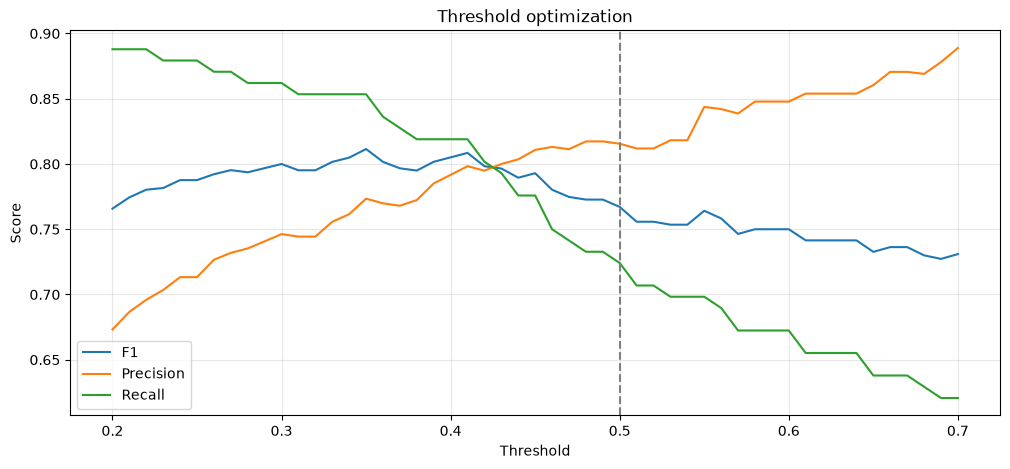

In [69]:
plt.figure(figsize=(12, 5))

plt.plot(threshold_results["threshold"],
         threshold_results["F1"], label="F1")

plt.plot(threshold_results["threshold"],
         threshold_results["Precision"], label="Precision")

plt.plot(threshold_results["threshold"],
         threshold_results["Recall"], label="Recall")

plt.axvline(0.5, linestyle="--", color="gray")

plt.xlabel("Threshold")
plt.ylabel("Score")
plt.title("Threshold optimization")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

### 8.2. Валидация оптимизированного порога

In [70]:
from sklearn.model_selection import StratifiedKFold

inner_cv = StratifiedKFold(
    n_splits=4,
    shuffle=True,
    random_state=42
)

nested_results = []

for fold, (train_idx, test_idx) in enumerate(cv.split(X, y), 1):

    X_train = X.iloc[train_idx]
    X_test = X.iloc[test_idx]

    y_train = y.iloc[train_idx]
    y_test = y.iloc[test_idx]

    # Подбираем порог только на обучающих данных
    train_probs = cross_val_predict(
        build_model(),
        X_train,
        y_train,
        cv=inner_cv,
        method="predict_proba"
    )[:, 1]

    best_threshold = max(
        np.arange(0.20, 0.71, 0.01),
        key=lambda t: f1_score(
            y_train, (train_probs >= t).astype(int)
        )
    )

    # Обучаем модель и проверяем на внешнем фолде
    model = build_model()
    model.fit(X_train, y_train)

    test_probs = model.predict_proba(X_test)[:, 1]

    nested_results.append({
        "fold": fold,
        "threshold": best_threshold,
        "F1_original": f1_score(
            y_test, (test_probs >= 0.5).astype(int)
        ),
        "F1_optimized": f1_score(
            y_test, (test_probs >= best_threshold).astype(int)
        )
    })

nested_results = pd.DataFrame(nested_results)

display(nested_results.round(4))
display(nested_results.mean().round(4))

,fold,threshold,F1_original,F1_optimized
0,1,0.36,0.8085,0.8235
1,2,0.55,0.7317,0.7317
2,3,0.43,0.7619,0.8000
3,4,0.55,0.7273,0.7273
4,5,0.25,0.8000,0.8333


fold            3.0000
threshold       0.4280
F1_original     0.7659
F1_optimized    0.7832
dtype: float64

### 8.3. Исследование силы регуляризации

In [71]:
C_values = [
    0.001, 0.003,
    0.01, 0.03,
    0.1, 0.3,
    1.0, 3.0,
    10.0, 30.0, 100.0
]

regularization_results = []

for C in C_values:

    scores = cross_validate(
        build_model(C=C),
        X,
        y,
        cv=cv,
        scoring=["f1", "precision", "recall", "roc_auc"]
    )

    regularization_results.append({
        "C": C,
        "F1": scores["test_f1"].mean(),
        "F1_std": scores["test_f1"].std(),
        "Precision": scores["test_precision"].mean(),
        "Recall": scores["test_recall"].mean(),
        "ROC_AUC": scores["test_roc_auc"].mean()
    })

regularization_results = pd.DataFrame(
    regularization_results
)

display(
    regularization_results
    .sort_values("F1", ascending=False)
    .round(4)
)

,C,F1,F1_std,Precision,Recall,ROC_AUC
5,0.300,0.7791,0.0351,0.8360,0.7330,0.8925
8,10.000,0.7718,0.0659,0.7913,0.7576,0.8860
7,3.000,0.7717,0.0665,0.8116,0.7402,0.8935
6,1.000,0.7659,0.0336,0.8172,0.7239,0.8955
9,30.000,0.7491,0.0705,0.7709,0.7319,0.8825
4,0.100,0.7485,0.0287,0.8376,0.6812,0.8848
2,0.010,0.7451,0.0455,0.9114,0.6380,0.8696
3,0.030,0.7339,0.0394,0.8646,0.6467,0.8785
10,100.000,0.7307,0.0699,0.7542,0.7149,0.8792
1,0.003,0.7021,0.0856,0.9467,0.5685,0.8570


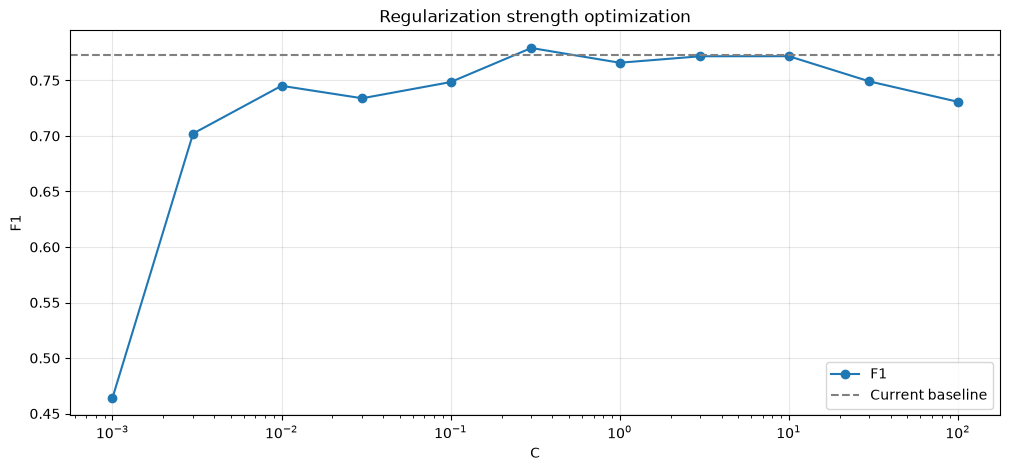

In [72]:
plt.figure(figsize=(12, 5))

plt.plot(
    regularization_results["C"],
    regularization_results["F1"],
    marker="o",
    label="F1"
)

plt.axhline(
    0.7730,
    color="gray",
    linestyle="--",
    label="Current baseline"
)

plt.xscale("log")
plt.xlabel("C")
plt.ylabel("F1")
plt.title("Regularization strength optimization")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

### 8.4. Сравнение Logistic Regression и CatBoost

In [73]:
from catboost import CatBoostClassifier

# Подготовка данных
X_cat = X.copy()

X_cat[final_numeric] = X_cat[final_numeric].replace(
    [np.inf, -np.inf], np.nan
)

for col in categorical:
    X_cat[col] = (
        X_cat[col].astype("string")
        .fillna("unknown")
        .astype(str)
    )

# Создание модели
catboost_model = CatBoostClassifier(
    iterations=300,
    depth=4,
    learning_rate=0.03,
    random_seed=42,
    verbose=False,
    allow_writing_files=False
)

# Кросс-валидация
catboost_scores = cross_validate(
    catboost_model,
    X_cat,
    y,
    cv=cv,
    scoring=["f1", "precision", "recall", "roc_auc"],
    params={"cat_features": categorical},
    error_score="raise"
)

# Расчёт метрик
catboost_results = {
    "F1": catboost_scores["test_f1"].mean(),
    "F1_std": catboost_scores["test_f1"].std(),
    "Precision": catboost_scores["test_precision"].mean(),
    "Recall": catboost_scores["test_recall"].mean(),
    "ROC_AUC": catboost_scores["test_roc_auc"].mean()
}

# Сравнение моделей
display(pd.DataFrame({
    "Logistic Regression": evaluate_features(
        final_numeric, categorical
    ),
    "CatBoost": catboost_results
}).T.round(4))

,F1,F1_std,Precision,Recall,ROC_AUC
Logistic Regression,0.7659,0.0336,0.8172,0.7239,0.8955
CatBoost,0.7594,0.0543,0.8267,0.7152,0.8875


### 8.5. Проверка исторических признаков продавцов

In [74]:
seller_block_features = [
    "seller_previous_blocks",
    "seller_block_rate",
    "seller_has_block_history"
]

seller_activity_features = [
    "seller_previous_listings",
    "seller_previous_expired",
    "seller_previous_removed",
    "seller_expired_rate"
]

seller_experiments = {
    "Original": final_numeric,

    "Block history": (
        final_numeric + seller_block_features
    ),

    "Seller activity": (
        final_numeric + seller_activity_features
    ),

    "All seller features": (
        final_numeric
        + seller_block_features
        + seller_activity_features
    )
}

seller_results = pd.DataFrame({
    name: evaluate_features(cols, categorical)
    for name, cols in seller_experiments.items()
}).T

display(seller_results.round(4))

,F1,F1_std,Precision,Recall,ROC_AUC
Original,0.7659,0.0336,0.8172,0.7239,0.8955
Block history,0.7613,0.0304,0.7953,0.7330,0.8891
Seller activity,0.7894,0.0402,0.8266,0.7583,0.8947
All seller features,0.7717,0.0360,0.8084,0.7413,0.8896


In [75]:
print("Размеченных объявлений с историей продавца:")
print((research["seller_previous_listings"] > 0).sum())

print("\nРазмеченных объявлений с историей блокировок:")
print(research["seller_has_block_history"].sum())

Размеченных объявлений с историей продавца:
116

Размеченных объявлений с историей блокировок:
2


### 8.2. Сохранение CSV
Перед экспортом присоединяем признаки из `feature/chat_features.csv` по `listing_id`. Суммируем число оценённых сообщений, берём максимальный сигнал каждого знака и пересчитываем итоговый балл и силу сигнала для объявления. Для объявлений без оценённых чатов используем нули. Сохраняем эти признаки в обеих таблицах.

Модель использует features.csv. В этот экспорт добавляем этапы разговора и повторные контакты покупателей. При экспорте убираем число длинных чатов и долю сообщений в самом длинном чате. Вместе их исключение повысило F1 и снизило ошибку долей по категориям. Исследовательские расчёты выше используют исходные признаки. В сокращённую таблицу входят ID, отобранные ранее признаки и признаки из текста чатов. Разметка не сохраняется в таблицах признаков. Сохраняем также обработанные surveys, events и messages с исходными столбцами последних двух таблиц.

In [76]:
chat_features = pd.read_csv("feature/chat_features.csv")

listing_chat_features = chat_features.groupby("listing_id").agg(
    scored_message_count=("scored_message_count", "sum"),
    strongest_positive_signal=("strongest_positive_signal", "max"),
    strongest_negative_signal=("strongest_negative_signal", "max")
)

listing_chat_features["deal_signal_score"] = (
    listing_chat_features["strongest_positive_signal"]
    - listing_chat_features["strongest_negative_signal"]
)

listing_chat_features["deal_signal_strength"] = (
    listing_chat_features[
        ["strongest_positive_signal", "strongest_negative_signal"]
    ].max(axis=1)
)

chat_feature_columns = listing_chat_features.columns.tolist()

features = features.drop(
    columns=chat_feature_columns,
    errors="ignore"
).join(
    listing_chat_features,
    on="listing_id",
    how="left",
    validate="one_to_one"
)

features[chat_feature_columns] = (
    features[chat_feature_columns].fillna(0)
)

features["scored_message_count"] = (
    features["scored_message_count"].astype(int)
)

In [77]:
# Сезонные признаки

features = features.copy()

month = pd.to_datetime(
    features["published_at"],
    errors="coerce",
    format="mixed"
).dt.month

keys = [features["base_title"], month]

# 1. Сезонная популярность товара

for metric in ["views_per_day", "contacts_per_day"]:

    all_median = (
        features.groupby("base_title")[metric]
        .transform("median")
    )

    monthly_group = features.groupby(keys)[metric]

    month_median = monthly_group.transform("median")
    group_size = monthly_group.transform("count")

    month_median = month_median.where(
        group_size >= 15, all_median
    ).where(month.notna())

    features[f"seasonal_{metric}"] = (
        month_median / all_median.replace(0, np.nan)
    )

# 2. Сезонная конверсия просмотров в контакты

contacts = (
    features["chats_total"]
    + features["phone_views_total"]
)

views = features["views_total"]

all_contacts = contacts.groupby(
    features["base_title"]
).transform("sum")

all_views = views.groupby(
    features["base_title"]
).transform("sum")

all_cr = all_contacts / all_views.replace(0, np.nan)

monthly_contacts = contacts.groupby(keys).transform("sum")
monthly_views = views.groupby(keys).transform("sum")
monthly_size = views.groupby(keys).transform("count")

monthly_cr = (
    monthly_contacts / monthly_views.replace(0, np.nan)
)

monthly_cr = monthly_cr.where(
    monthly_size >= 15, all_cr
).where(month.notna())

features["seasonal_contact_conversion"] = (
    monthly_cr / all_cr.replace(0, np.nan)
)

seasonal_columns = [
    "seasonal_views_per_day",
    "seasonal_contacts_per_day",
    "seasonal_contact_conversion"
]

display(features[seasonal_columns].describe())

,seasonal_views_per_day,seasonal_contacts_per_day,seasonal_contact_conversion
count,15234.000000,15234.000000,15234.000000
mean,1.001353,0.998412,1.001195
std,0.077058,0.078405,0.036412
min,0.715712,0.778406,0.850379
25%,0.959024,0.949331,0.978604
50%,1.000000,1.000000,1.000211
75%,1.034635,1.041226,1.022260
max,1.545449,1.359747,1.204268


In [78]:
OUTPUT = Path("data_by_dewallen")
OUTPUT.mkdir(exist_ok=True)

best_export_features = final_feature_columns + chat_feature_columns
excluded_features = ["long_chats_count", "dominant_chat_share"]
model_features = features.drop(columns=excluded_features).merge(
    dialogue_features.reset_index(), on="listing_id", how="left", validate="one_to_one"
).merge(
    buyer_contact_features.reset_index(), on="listing_id", how="left", validate="one_to_one"
).merge(
    cross_chat_features, on="listing_id", how="left", validate="one_to_one"
)

assert model_features[cross_chat_column].isin([0, 1]).all()
assert model_features["listing_id"].is_unique, "Повторяются ID объявлений"
assert len(model_features) == len(listings), "Изменилось число объявлений"
assert not model_features.columns.isin(excluded_features).any(), "Лишние признаки в экспорте"

model_features.to_csv(OUTPUT / "features.csv", index=False)
print("Столбцов в features.csv:", model_features.shape[1])
features[["listing_id"] + best_export_features].to_csv(
    OUTPUT / "best_features.csv", index=False
)
surveys.to_csv(OUTPUT / "surveys.csv", index=False)
events_clean[events.columns].to_csv(OUTPUT / "events.csv", index=False)
messages_clean[messages.columns].to_csv(OUTPUT / "messages.csv", index=False)

for path in sorted(OUTPUT.glob("*.csv")):
    print("Сохранено:", path)
print("Папка:", OUTPUT.resolve())

Столбцов в features.csv: 137
Сохранено: data_by_dewallen\best_features.csv
Сохранено: data_by_dewallen\events.csv
Сохранено: data_by_dewallen\features.csv
Сохранено: data_by_dewallen\messages.csv
Сохранено: data_by_dewallen\survey_deal_labels.csv
Сохранено: data_by_dewallen\survey_deal_listings.csv
Сохранено: data_by_dewallen\surveys.csv
Сохранено: data_by_dewallen\verified_relative_price.csv
Папка: C:\Users\sbitw\neuroslop_kygarikovs_hakaton\data_by_dewallen


### 8.3. Контроль экспортированных таблиц
Повторно читаем CSV и проверяем размеры и ключи. Для сравнения качества используем командный модуль `f1.py` (или его исходное имя `f1_check.py`, если файл ещё не переименован). Полная таблица включает также заголовки, даты и дублирующие столбцы; такой эксперимент не является чистым сравнением инженерных признаков. Если модуль отсутствует, основной ноутбук всё равно завершает работу.

In [79]:
full_df = pd.read_csv(OUTPUT / "features.csv")
best_df = pd.read_csv(OUTPUT / "best_features.csv")
assert full_df["listing_id"].is_unique and best_df["listing_id"].is_unique
assert full_df["listing_id"].equals(best_df["listing_id"])
assert len(best_df) == len(listings)
assert best_df.columns.tolist() == ["listing_id"] + best_export_features

full_df = full_df.merge(verified, on="listing_id", how="inner", validate="one_to_one")
best_df = best_df.merge(verified, on="listing_id", how="inner", validate="one_to_one")
print("All features (столбцы без ID и target):", full_df.drop(columns=["listing_id", "seller_id", "is_deal"], errors="ignore").shape[1])
print("Best features:", len(best_export_features))

from importlib.util import find_spec

if find_spec("f1") is not None:
    from f1 import evaluate_features as check_f1
elif find_spec("f1_check") is not None:
    from f1_check import evaluate_features as check_f1
else:
    check_f1 = None
    print("Командный модуль f1.py не найден. Сравнение CSV пропущено.")

if check_f1 is not None:
    export_results = pd.DataFrame({
        "All features": check_f1(full_df),
        "Best features": check_f1(best_df)
    }).T
    display(export_results.round(4))

All features (столбцы без ID и target): 135
Best features: 65


,F1,F1_std,Precision,Recall,ROC_AUC
All features,0.8375,0.0367,0.8612,0.8188,0.9339
Best features,0.7559,0.0308,0.7952,0.7243,0.8870


### 8.4. Проверка итоговой модели

Запустите `models/model.ipynb` для оценки на пяти фолдах, расчёта ошибки долей по категориям и сохранения `models/submission.csv`.